In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels
import statsmodels.api as sm
from statsmodels import stats
from statsmodels.stats import weightstats as ssw
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd


df = pd.read_excel("Application_Based_Statistics_Dataset.xlsx")


TRAINING PROGRAM — PAIRED t-TEST

1. Appropriate Graph

The appropriate graph is a paired line graph because the dataset contains two numerical variables (Pre-Test and Post-Test) measured on the same students.

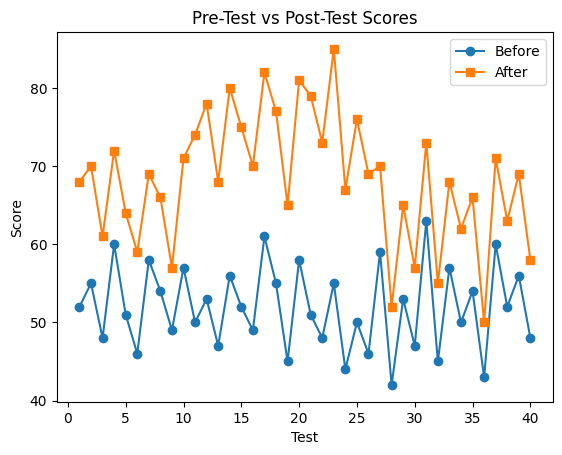

In [6]:
# 2. Graph Code
plt.plot(df["Student_ID"], df["Pre_Test"], marker="o", label="Before")
plt.plot(df["Student_ID"], df["Post_Test"], marker="s", label="After")
plt.legend()
plt.xlabel("Test")
plt.ylabel("Score")
plt.title("Pre-Test vs Post-Test Scores")
plt.show()

3. Graph Conclusion

The graph shows that most students have higher Post-Test scores than Pre-Test scores, indicating an overall improvement after the training program.

4. Hypotheses

Let:    d = Post_Test - Pre_Test 

H₀: The mean improvement is zero.
      H_0:   mu_d=0 

H₁: The mean improvement is greater than zero.
      H_1:   mu_d>0 


5. Appropriate Statistical Test

The appropriate test is the paired-sample t-test because there are two numerical measurements, the outcome is numerical, and the observations are paired because the same students were measured before and after training.

In [7]:
# 6. Test Code
df["Difference"] = df["Post_Test"] - df["Pre_Test"]

data = ssw.DescrStatsW(df["Difference"])

t_stat, p_value, df_test = data.ttest_mean(
    value=0,
    alternative="larger"
)

print("t-statistic =", t_stat)
print("p-value =", p_value)
print("df =", df_test)

t-statistic = 16.105365233905978
p-value = 3.9728545989557e-19
df = 39.0


7. Test Result

Test statistic = 16.105

p-value ≈ 3.97 × 10⁻¹⁹

8. Decision

Since p-value < 0.05, we reject H₀.

9. Final Conclusion

At the 5% significance level, there is sufficient evidence to conclude that the training program significantly improved the students' scores.

THREE TEACHING METHODS — ONE-WAY ANOVA

1. Appropriate Graph

The appropriate graph is a multiple boxplot because the dataset contains one numerical variable (Post-Test/Final Score) across three categorical groups (Teaching Methods A, B and C).

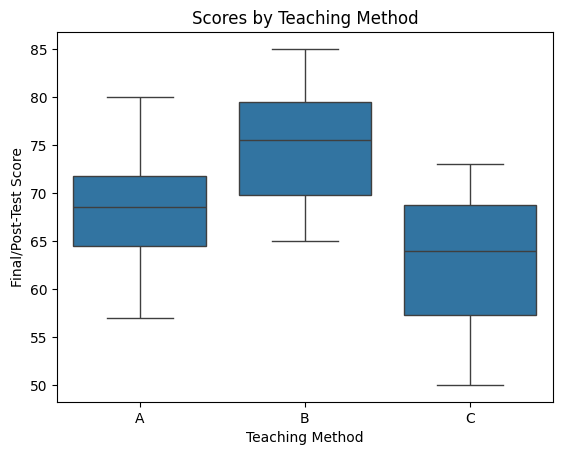

In [8]:
# 2. Graph Code
sns.boxplot(
    x="Teaching_Method",
    y="Post_Test",
    data=df
)

plt.xlabel("Teaching Method")
plt.ylabel("Final/Post-Test Score")
plt.title("Scores by Teaching Method")
plt.show()

3. Graph Conclusion

The graph shows that Teaching Method B has the highest median/mean score, while Method C has the lowest. The boxplots also show differences in the spread of scores among the three methods.

4. Hypotheses

H₀:  mu_A=mu_B=mu_C 

There is no significant difference among the three population means.

H₁:  At least one population mean is different.

5. Appropriate Statistical Test

The appropriate test is the one-way ANOVA because there is one categorical independent variable with three groups, the outcome is numerical, and the objective is to compare the mean scores of more than two independent groups.

In [11]:
# 6. Test Code
model = ols(
    "Post_Test ~ C(Teaching_Method)",
    data=df
).fit()

anova_table = sm.stats.anova_lm(
    model,
    typ=2
)

print(anova_table)


print("-----------------------------------------")
tukey = pairwise_tukeyhsd(
    endog=df["Post_Test"],
    groups=df["Teaching_Method"],
    alpha=0.05
)

print(tukey)

                         sum_sq    df          F    PR(>F)
C(Teaching_Method)   950.886905   2.0  10.248488  0.000287
Residual            1716.488095  37.0        NaN       NaN
-----------------------------------------
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B   6.5595 0.0493   0.0176 13.1015   True
     A      C  -5.5714 0.0909 -11.8567  0.7139  False
     B      C  -12.131 0.0002 -18.6729  -5.589   True
-----------------------------------------------------


7. Test Result

Test statistic:
   F=10.248 

p-value:
   p=0.000287
    
8. Decision

Since p-value < 0.05, we reject H₀.

9. Final Conclusion

At the 5% significance level, there is sufficient evidence to conclude that there is a statistically significant difference in the mean scores among the three teaching methods.

TEACHING METHOD vs PASS/FAIL — CHI-SQUARE ASSOCIATION

1. Appropriate Graph

The appropriate graph is a stacked bar chart because the dataset contains two categorical variables: Teaching Method and Pass/Fail status.

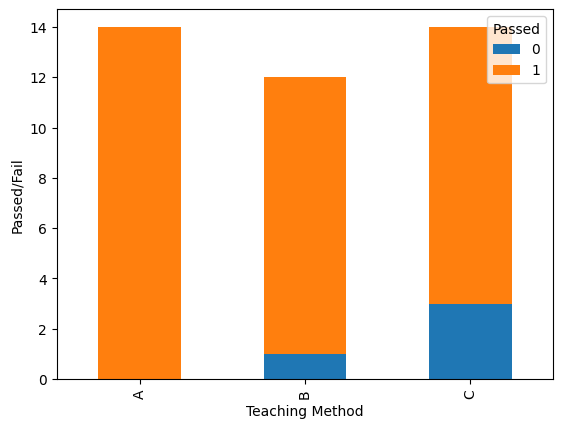

In [12]:
# 2. Graph code 
graph = pd.crosstab(df["Teaching_Method"],df["Passed"])
graph.plot(kind="bar",stacked=True)
plt.xlabel("Teaching Method")
plt.ylabel("Passed/Fail")
plt.show()

3. Graph Conclusion

The graph shows that the proportion of students passing differs across the teaching methods, although the visual difference must be tested statistically to determine whether the association is significant.

4. Hypotheses

H₀:  Teaching Method and Pass/Fail status are independent.

H₁:  Teaching Method and Pass/Fail status are associated.

5. Appropriate Statistical Test

The appropriate test is the Chi-square test of association because there are two categorical variables, namely Teaching Method and Pass/Fail status, and the objective is to determine whether they are associated.

In [13]:
# 6. Test Code
table = pd.crosstab(
    df["Teaching_Method"],
    df["Passed"]
)

chi_test = statsmodels.stats.contingency_tables.Table(
    table,
    shift_zeros=False
).test_nominal_association()

print("Chi-square =", chi_test.statistic)
print("df =", chi_test.df)
print("p-value =", chi_test.pvalue)

Chi-square = 3.6243386243386237
df = 2
p-value = 0.1632995046851362


7. Test Result

Test statistic:  chi^2=3.624 

Degrees of freedom: df=2 

p-value: p=0.1633 

8. Decision

Since p-value > 0.05, we fail to reject H₀.

9. Final Conclusion

At the 5% significance level, there is insufficient evidence to conclude that Teaching Method and Pass/Fail status are associated.

MALE vs FEMALE — TWO-SAMPLE t-TEST

1. Appropriate Graph

The appropriate graph is a boxplot because the dataset contains one numerical variable (Post-Test Score) compared across two categorical groups (Male and Female).

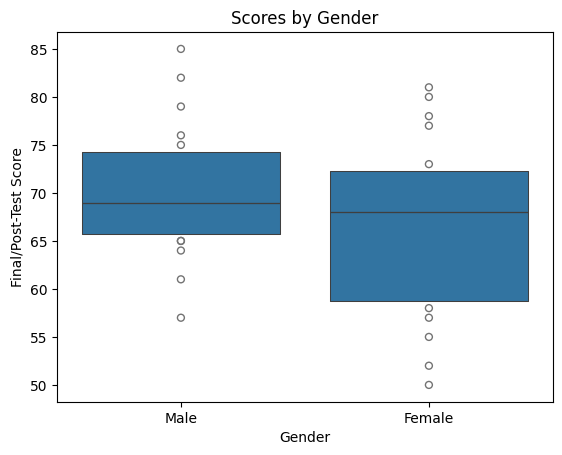

In [14]:
# 2. Graph code 
sns.boxenplot(x="Gender",y="Post_Test",data=df)
plt.xlabel("Gender")
plt.ylabel("Final/Post-Test Score")
plt.title("Scores by Gender")
plt.show()

3. Graph Conclusion

The graph shows that the male group has a higher sample mean/median score than the female group, but statistical testing is required to determine whether the difference is significant.

4. Hypotheses

Let:
   mu_M = {mean score of males}  
   mu_F = {mean score of females} 

H₀: mu_M = mu_F 

H₁: mu_M != mu_F

5. Appropriate Statistical Test

The appropriate test is the independent two-sample t-test because there are two independent groups, the outcome is numerical, and the objective is to compare the mean scores of males and females.

In [15]:
# 6. Test Code
male = df[df["Gender"] == "Male"]["Post_Test"]
female = df[df["Gender"] == "Female"]["Post_Test"]

test = ssw.CompareMeans(
    ssw.DescrStatsW(male),
    ssw.DescrStatsW(female)
)

t_stat, p_value, df_test = test.ttest_ind(
    alternative="two-sided",
    usevar="unequal"
)

print("t-statistic =", t_stat)
print("p-value =", p_value)
print("df =", df_test)

t-statistic = 1.454259564715746
p-value = 0.15475318945955244
df = 35.12236266846113


7. Test Result

Test statistic: t=1.454

p-value:  p=0.1548 

8. Decision

Since p-value > 0.05, we fail to reject H₀.

9. Final Conclusion

At the 5% significance level, there is insufficient evidence to conclude that the mean scores of male and female students are significantly different.